# Credit Card Customer Segmentation
## Phase 3: K-Means Clustering

**Objective:** Identify meaningful customer segments using the K-Means unsupervised machine learning algorithm.

The optimal number of clusters will be investigated using the Elbow Method and Silhouette Score.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

# Locate project root
PROJECT_ROOT = Path.cwd().parent

# Define file paths
DATA_PATH = (
    PROJECT_ROOT / "data" / "processed"
    / "credit_card_customer_features_scaled.csv"
)

ARTIFACT_PATH = (
    PROJECT_ROOT / "models"
    / "preprocessing_artifacts.joblib"
)

# Validate paths
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

if not ARTIFACT_PATH.exists():
    raise FileNotFoundError(f"Artifacts not found: {ARTIFACT_PATH}")

# Load processed data
processed_df = pd.read_csv(DATA_PATH)

# Load preprocessing artifacts
preprocessing_artifacts = joblib.load(ARTIFACT_PATH)

# Separate customer IDs and clustering features
customer_ids = processed_df["CUST_ID"].copy()
X = processed_df.drop(columns=["CUST_ID"])

# Validate feature consistency
expected_features = preprocessing_artifacts["selected_features"]

assert X.columns.tolist() == expected_features
assert X.shape == (8950, 16)
assert X.isnull().sum().sum() == 0

print("Processed dataset loaded successfully!")
print("Customer records:", len(customer_ids))
print("Clustering features:", X.shape[1])
print("Clustering matrix shape:", X.shape)
print("Missing values:", X.isnull().sum().sum())

display(X.head())

Processed dataset loaded successfully!
Customer records: 8950
Clustering features: 16
Clustering matrix shape: (8950, 16)
Missing values: 0


,BALANCE,BALANCE_FREQUENCY,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,-1.205218,-0.249434,-0.987090,0.394480,-0.930733,-0.806490,-0.678661,-0.707313,-0.675349,-0.810069,-0.579510,-1.447163,-0.824484,-0.829841,-0.525551,0.36068
1,0.948918,0.134325,-0.987090,-1.087454,1.528788,-1.221758,-0.678661,-0.916995,0.573963,0.784603,-1.379210,0.926060,1.065033,0.908184,0.234227,0.36068
2,0.824993,0.518084,1.062022,-1.087454,-0.930733,1.269843,2.673451,-0.916995,-0.675349,-0.810069,0.487865,1.010229,-0.119300,0.450407,-0.525551,0.36068
3,0.624653,-1.016953,1.265778,-1.087454,0.564372,-1.014125,-0.399319,-0.916995,-0.258913,-0.123281,-0.874655,1.010229,-4.161996,-0.144271,-0.525551,0.36068
4,0.271260,0.518084,-0.114307,-1.087454,-0.930733,-1.014125,-0.399319,-0.916995,-0.675349,-0.810069,-0.874655,-1.224909,-0.064979,-0.351833,-0.525551,0.36068


## 2. Finding the Optimal Number of Clusters

Evaluate K-Means clustering for different values of K using:

1. Elbow Method (Within-Cluster Sum of Squares / Inertia)
2. Silhouette Score

The objective is to identify an appropriate number of customer segments based on clustering quality and interpretability.

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Define the range of cluster counts
k_values = range(2, 11)

# Store evaluation results
inertia_values = []
silhouette_values = []
kmeans_models = {}

# Evaluate different cluster counts
for k in k_values:

    print(f"Evaluating K = {k}...")

    # Initialise K-Means
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        max_iter=300,
        random_state=42
    )

    # Fit the model
    labels = kmeans.fit_predict(X)

    # Calculate inertia
    inertia_values.append(kmeans.inertia_)

    # Calculate approximate silhouette score
    score = silhouette_score(
        X,
        labels,
        sample_size=2000,
        random_state=42
    )

    silhouette_values.append(score)

    # Store model
    kmeans_models[k] = kmeans

# Create evaluation report
evaluation_df = pd.DataFrame({
    "Number of Clusters (K)": list(k_values),
    "Inertia (WCSS)": inertia_values,
    "Silhouette Score": silhouette_values
})

print("\nK-MEANS EVALUATION RESULTS")
display(evaluation_df.round(4))

Evaluating K = 2...
Evaluating K = 3...
Evaluating K = 4...
Evaluating K = 5...
Evaluating K = 6...
Evaluating K = 7...
Evaluating K = 8...
Evaluating K = 9...
Evaluating K = 10...

K-MEANS EVALUATION RESULTS


,Number of Clusters (K),Inertia (WCSS),Silhouette Score
0,2,109060.2685,0.2300
1,3,92090.2744,0.2202
2,4,82974.7777,0.2185
3,5,75294.2586,0.2242
4,6,69543.1250,0.2096
5,7,65534.7881,0.2158
6,8,62510.8783,0.2096
7,9,58907.1309,0.1761
8,10,56306.6023,0.1772


## 3.1 Visualising Cluster Evaluation Results

The evaluation results obtained for different values of K are visualised using two plots: the Elbow Method and the Silhouette Score.

### 1. Elbow Method Plot

The Elbow Method plot illustrates the relationship between the number of clusters (K) and the Within-Cluster Sum of Squares (WCSS), represented by inertia.

As K increases, inertia decreases because customers are divided into more clusters. We examine the plot to identify the point at which the rate of decrease starts slowing down. This point provides a potential choice for the optimal number of clusters.

### 2. Silhouette Score Plot

The Silhouette Score plot compares the clustering quality across different values of K.

A higher silhouette score generally indicates better-defined clusters, with customers being more similar to members of their own cluster than to members of other clusters.

### Objective

The purpose of these visualisations is to:

- Identify potential optimal K values using the Elbow Method.
- Compare clustering quality using Silhouette Scores.
- Shortlist suitable K values for further evaluation.

The final number of clusters will be selected after examining these plots and evaluating the resulting cluster sizes and customer behaviour profiles.

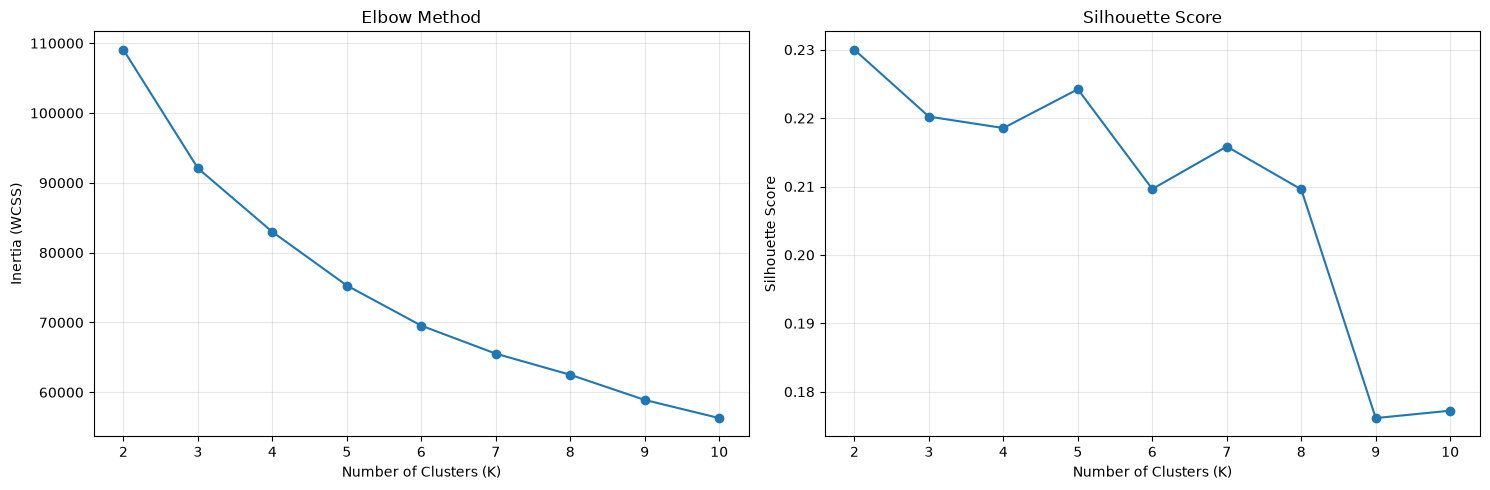

Evaluation graphs saved to: c:\Users\ka100\OneDrive\Desktop\Credit-Card-Customer-Segmentation\outputs\plots\kmeans_cluster_evaluation.png


In [3]:
# Plot Elbow Method and Silhouette Score

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Elbow Method
axes[0].plot(list(k_values), inertia_values, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia (WCSS)")
axes[0].set_xticks(list(k_values))
axes[0].grid(alpha=0.3)

# 2. Silhouette Score
axes[1].plot(list(k_values), silhouette_values, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))
axes[1].grid(alpha=0.3)

plt.tight_layout()

# Save the evaluation plot
output_path = PROJECT_ROOT / "outputs" / "plots" / "kmeans_cluster_evaluation.png"
output_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Evaluation graphs saved to: {output_path}")

## 3.2 Interpretation of Cluster Evaluation Results

The Elbow Method and Silhouette Score plots were examined to identify suitable values of K for customer segmentation.

### Elbow Method Observations

- Inertia decreases substantially as the number of clusters increases from K=2 to K=5.
- Beyond approximately K=5–6, the reduction in inertia becomes more gradual.
- This suggests that K=5 or K=6 may provide a reasonable balance between clustering performance and model complexity.

### Silhouette Score Observations

- K=2 achieves the highest silhouette score of 0.2300.
- K=5 achieves a score of 0.2242.
- K=3 achieves a score of 0.2202.
- The relatively modest scores indicate that the resulting customer clusters may have some overlap.

### Preliminary Conclusion

Based on both evaluation methods, K=2, K=3, K=5 and K=6 are shortlisted for further investigation.

The final number of clusters will be determined by examining cluster sizes, customer distribution and behavioural characteristics. The highest silhouette score alone will not determine the final model.

## 3.3 Cluster Size Distribution Analysis

After evaluating the Elbow Method and Silhouette Scores, the shortlisted K values (2, 3, 5 and 6) are further examined through cluster size distribution analysis.

This analysis measures how customers are distributed across the clusters for each K value.

### Objective

- Determine the number of customers assigned to each cluster.
- Calculate the percentage of customers in each cluster.
- Identify highly concentrated or extremely small clusters.
- Compare the customer distribution across the shortlisted K values.

This analysis helps assess whether the resulting clusters have reasonable customer representation before proceeding to customer behaviour profiling.

In [4]:
# Compare cluster sizes for shortlisted K values

candidate_ks = [2, 3, 5, 6]

cluster_size_results = []

for k in candidate_ks:

    labels = kmeans_models[k].labels_

    cluster_counts = pd.Series(labels).value_counts().sort_index()

    for cluster_id, count in cluster_counts.items():

        cluster_size_results.append({
            "K": k,
            "Cluster": cluster_id,
            "Customer Count": count,
            "Percentage (%)": round(
                (count / len(X)) * 100, 2
            )
        })

cluster_sizes_df = pd.DataFrame(cluster_size_results)

display(cluster_sizes_df)

,K,Cluster,Customer Count,Percentage (%)
0,2,0,5326,59.51
1,2,1,3624,40.49
2,3,0,2776,31.02
3,3,1,3049,34.07
4,3,2,3125,34.92
5,5,0,1851,20.68
6,5,1,1204,13.45
7,5,2,2752,30.75
8,5,3,1287,14.38
9,5,4,1856,20.74


### 3.3.1 Interpretation of Cluster Size Distribution

The cluster size distribution was analysed for the shortlisted K values (2, 3, 5 and 6) to understand how customers are grouped by the K-Means algorithm.

### Observations

**K = 2**
- Cluster 0 contains 5,326 customers (59.51%).
- Cluster 1 contains 3,624 customers (40.49%).
- The distribution is reasonably balanced, but provides only two broad customer segments.

**K = 3**
- The three clusters contain 31.02%, 34.07% and 34.92% of customers, respectively.
- The customer distribution is nearly balanced across all three clusters.

**K = 5**
- The five clusters contain between 13.45% and 30.75% of customers.
- All clusters have sufficient customer representation for further behavioural analysis.
- This configuration provides more granular segmentation than K = 2 or K = 3.

**K = 6**
- The six clusters contain between 11.63% and 27.06% of customers.
- All six clusters contain more than 1,000 customers.
- This configuration provides the most detailed segmentation among the shortlisted candidates.

### Preliminary Conclusion

All four candidate models produce clusters with reasonable customer representation, without extremely small clusters.

K = 5 is considered a promising candidate because it provides more detailed customer segmentation while maintaining a reasonable distribution and a relatively strong silhouette score.

However, cluster size alone is not sufficient to determine the optimal number of clusters. The final decision will be made after analysing the behavioural characteristics and distinctiveness of the resulting customer segments.

## 3.4.1 Customer Behaviour Profiling

After evaluating cluster quality and customer distribution, the next step is to analyse the behavioural characteristics of customers assigned to each cluster.

Cluster profiling helps identify differences in customer spending patterns, purchase frequency, cash advances, account balances and payment behaviour.

### Profiling Approach

- Analyse the shortlisted K = 3 and K = 5 models.
- Use the original, unscaled customer data to make the results easier to interpret.
- Calculate the mean and median values of customer features within each cluster.
- Compare the behavioural characteristics of the resulting clusters.

### Why Mean and Median?

- **Mean:** Represents the average behaviour of customers within a cluster. It can be influenced by extreme values.
- **Median:** Represents the middle value and is less affected by extreme values and skewed distributions.

### Objective

The objective is to identify meaningful differences between customer groups and determine whether five clusters provide more useful customer segmentation than three clusters.

In [9]:
# Generate and export customer behaviour profiles

from pathlib import Path

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "CC GENERAL.csv"
REPORT_PATH = PROJECT_ROOT / "outputs" / "reports" / "customer_cluster_profiles.xlsx"

raw_df = pd.read_csv(RAW_DATA_PATH)

# Verify customer alignment
assert len(raw_df) == len(X), "Customer count mismatch!"

assert (
    raw_df["CUST_ID"].astype(str).reset_index(drop=True)
    .equals(customer_ids.astype(str).reset_index(drop=True))
), "Customer IDs are not aligned!"

profile_features = raw_df.drop(columns=["CUST_ID"]).copy()

# Store all profiling results
profile_results = {}

for k in [3, 5]:

    profile_df = profile_features.copy()
    profile_df["Cluster"] = kmeans_models[k].labels_

    # Customer distribution
    distribution = (
        profile_df["Cluster"]
        .value_counts()
        .sort_index()
        .to_frame("Customer Count")
    )

    distribution["Percentage (%)"] = (
        distribution["Customer Count"] / len(profile_df) * 100
    ).round(2)

    # Mean and median profiles
    mean_profile = (
        profile_df.groupby("Cluster")
        .mean(numeric_only=True)
        .round(2)
    )

    median_profile = (
        profile_df.groupby("Cluster")
        .median(numeric_only=True)
        .round(2)
    )

    profile_results[k] = {
        "Distribution": distribution,
        "Mean": mean_profile,
        "Median": median_profile
    }

# Export all results into one Excel workbook
REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)

with pd.ExcelWriter(REPORT_PATH, engine="openpyxl") as writer:

    for k, results in profile_results.items():

        for table_name, table in results.items():

            sheet_name = f"K{k}_{table_name}"
            table.to_excel(writer, sheet_name=sheet_name)

print("Customer profiling completed successfully.")
print(f"Excel report saved at: {REPORT_PATH}")

# Display all results
for k, results in profile_results.items():

    print(f"\n========== K = {k} ==========")

    for table_name, table in results.items():

        print(f"\n{table_name} Profile:")
        display(table)

Customer profiling completed successfully.
Excel report saved at: c:\Users\ka100\OneDrive\Desktop\Credit-Card-Customer-Segmentation\outputs\reports\customer_cluster_profiles.xlsx

========== K = 3 ==========

Distribution Profile:


,Customer Count,Percentage (%)
Cluster,,
0,2776,31.02
1,3049,34.07
2,3125,34.92



Mean Profile:


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
Cluster,,,,,,,,,,,,,,,,,
0,188.32,0.70,451.11,166.40,285.22,43.08,0.52,0.08,0.42,0.01,0.15,8.09,3283.91,692.65,191.40,0.27,11.35
1,1953.79,0.98,2347.48,1438.28,909.48,644.96,0.86,0.46,0.64,0.09,2.11,33.87,5758.22,2624.36,1168.51,0.17,11.83
2,2407.09,0.93,182.06,145.63,36.57,2135.94,0.11,0.06,0.05,0.29,7.11,1.90,4336.37,1787.89,1120.12,0.03,11.37



Median Profile:


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
Cluster,,,,,,,,,,,,,,,,,
0,50.22,0.82,297.68,0.00,158.17,0.00,0.5,0.00,0.35,0.00,0.0,6.0,2500.0,387.73,146.99,0.08,12.0
1,1199.94,1.00,1490.63,764.16,522.17,0.00,1.0,0.42,0.75,0.00,0.0,24.0,5000.0,1607.05,468.47,0.00,12.0
2,1643.22,1.00,0.00,0.00,0.00,1331.17,0.0,0.00,0.00,0.25,4.0,0.0,3000.0,867.23,567.69,0.00,12.0


... (2 outputs left out)


Mean Profile:


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
Cluster,,,,,,,,,,,,,,,,,
0,483.54,0.93,681.80,45.43,637.18,34.99,0.80,0.03,0.76,0.01,0.13,14.81,3026.68,828.10,679.91,0.31,11.50
1,3422.17,0.98,1571.82,885.45,686.64,2686.91,0.75,0.32,0.58,0.34,9.22,25.62,6024.83,3064.20,1689.25,0.04,11.53
2,2261.61,0.94,99.08,91.36,7.76,1888.89,0.05,0.04,0.01,0.26,6.14,0.84,4114.31,1620.62,1058.96,0.03,11.42
3,89.84,0.43,326.41,234.71,91.93,141.05,0.25,0.09,0.15,0.02,0.42,3.83,3597.00,774.93,118.06,0.18,11.26
4,1426.27,0.97,2764.79,1938.91,826.11,43.82,0.82,0.61,0.50,0.01,0.15,35.65,6150.99,2603.58,649.49,0.24,11.85



Median Profile:


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
Cluster,,,,,,,,,,,,,,,,,
0,127.24,1.00,453.24,0.00,419.76,0.00,0.92,0.00,0.83,0.00,0.0,12.0,2000.0,539.97,174.36,0.1,12.0
1,2642.35,1.00,978.68,432.94,392.65,1795.09,0.83,0.25,0.61,0.29,6.0,16.0,5000.0,1794.34,1002.79,0.0,12.0
2,1543.24,1.00,0.00,0.00,0.00,1129.36,0.00,0.00,0.00,0.25,4.0,0.0,3000.0,772.87,517.59,0.0,12.0
3,22.49,0.36,160.00,24.64,0.00,0.00,0.17,0.08,0.00,0.00,0.0,3.0,2500.0,291.95,103.70,0.0,12.0
4,786.27,1.00,1798.59,1132.64,387.96,0.00,0.92,0.58,0.50,0.00,0.0,25.0,5725.0,1626.33,258.05,0.0,12.0


In [10]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
import openpyxl
print(openpyxl.__version__)

3.1.5


### 3.4.2 Interpretation of Customer Behaviour Profiles

Customer behaviour profiles were generated for K = 3 and K = 5 using the original, unscaled dataset. Both mean and median values were examined to understand the characteristics of each cluster.

### K = 3: Behavioural Interpretation

The three-cluster solution identifies the following broad customer groups:

- **Cluster 0 – Low-Balance, Moderate Purchasers:** Customers exhibit relatively low account balances and moderate purchasing activity, with a greater contribution from installment purchases.
- **Cluster 1 – Frequent, High-Spending Purchasers:** Customers demonstrate higher purchase amounts, frequent purchasing activity and a greater number of purchase transactions.
- **Cluster 2 – Cash-Advance-Dominant Customers:** Customers exhibit substantial cash-advance usage and relatively little purchase activity.

### K = 5: Behavioural Interpretation

The five-cluster solution provides more detailed customer segmentation:

- **Cluster 0 – Installment-Oriented Purchasers:** Customers primarily use installment purchases and demonstrate relatively frequent purchasing activity.
- **Cluster 1 – High-Balance, Mixed Cash-Advance Users:** Customers exhibit high account balances, substantial cash advances and considerable purchasing activity.
- **Cluster 2 – Cash-Advance-Dominant Customers:** Customers demonstrate substantial cash-advance usage with very limited purchase activity.
- **Cluster 3 – Low-Activity Customers:** Customers exhibit low account balances, relatively low purchase amounts and limited overall activity.
- **Cluster 4 – High-Spending, One-Off Purchasers:** Customers demonstrate high purchase amounts, with one-off purchases contributing substantially to their total spending.

### Comparative Analysis

The K = 3 model provides three broad behavioural categories, whereas K = 5 identifies more specific differences in installment purchases, one-off purchases, cash-advance usage and overall customer activity.

The five-cluster solution therefore provides additional behavioural detail that may be useful for developing targeted customer engagement strategies.

### Preliminary Model Selection

Based on the evaluation metrics, cluster distribution and behavioural interpretability, K = 5 is selected as the preferred candidate for further analysis.

Although K = 2 achieved the highest silhouette score, K = 5 provides a more detailed segmentation structure. Its silhouette score is also slightly higher than that of K = 3.

The silhouette scores remain relatively modest, indicating that some overlap may exist between customer segments. Therefore, the selected model should be interpreted as a practical behavioural segmentation rather than perfectly separated customer groups.

## 3.5 Visualising Customer Segments Using PCA

Principal Component Analysis (PCA) is a dimensionality reduction technique used to transform high-dimensional data into a smaller number of components while preserving as much variance as possible.

In this project, the customer dataset contains 16 scaled features. PCA is applied to reduce these features to two principal components for visualisation.

### Why PCA?

- Reduces the 16-dimensional feature space to two dimensions.
- Helps visualise the distribution of customer clusters.
- Provides a visual representation of similarities and differences between customer groups.
- Helps examine the degree of overlap among the identified clusters.

### Methodology

1. Apply PCA to the standardised customer features.
2. Extract the first two principal components.
3. Assign the previously generated K-Means cluster labels (K = 5).
4. Create a two-dimensional scatter plot to visualise the customer segments.
5. Calculate the explained variance ratio of the two principal components.

### Objective

The objective is to visually examine the five customer segments and understand how they are distributed in the reduced feature space.

PCA is used only for visualisation. The K-Means model continues to use all 16 standardised features.

PCA Explained Variance:
Principal Component 1: 0.3157
Principal Component 2: 0.2285
Total Explained Variance: 0.5442
Total Explained Variance (%): 54.42%


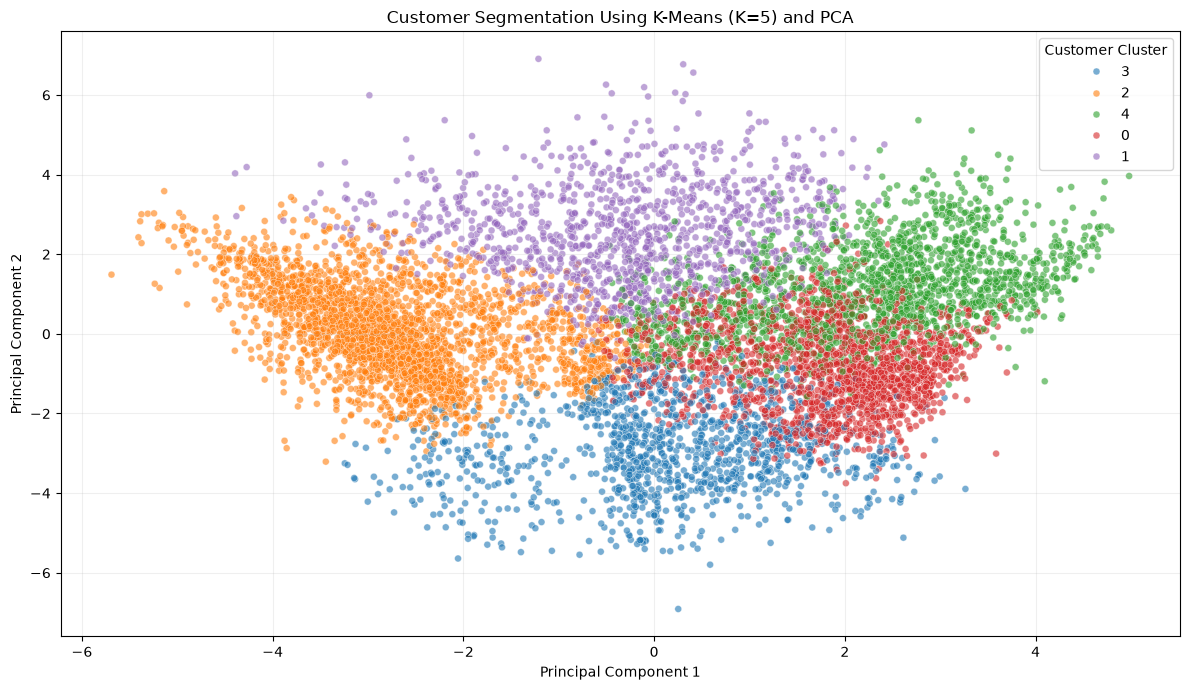


PCA visualisation saved to: c:\Users\ka100\OneDrive\Desktop\Credit-Card-Customer-Segmentation\outputs\plots\pca_customer_segmentation.png


In [12]:
# Import PCA
from sklearn.decomposition import PCA

# Select the preferred K-Means model
best_k = 5
final_kmeans = kmeans_models[best_k]

# Retrieve cluster labels
cluster_labels = final_kmeans.labels_

# Apply PCA to reduce 16 features to 2 components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

# Create a DataFrame for PCA results
pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal Component 1", "Principal Component 2"]
)

# Add cluster assignments
pca_df["Cluster"] = cluster_labels.astype(str)

# Calculate explained variance
explained_variance = pca.explained_variance_ratio_

print("PCA Explained Variance:")
print(f"Principal Component 1: {explained_variance[0]:.4f}")
print(f"Principal Component 2: {explained_variance[1]:.4f}")
print(f"Total Explained Variance: {explained_variance.sum():.4f}")
print(
    f"Total Explained Variance (%): "
    f"{explained_variance.sum() * 100:.2f}%"
)

# Visualise the clusters
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=pca_df,
    x="Principal Component 1",
    y="Principal Component 2",
    hue="Cluster",
    palette="tab10",
    alpha=0.6,
    s=25
)

plt.title("Customer Segmentation Using K-Means (K=5) and PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Customer Cluster")
plt.grid(alpha=0.2)
plt.tight_layout()

# Save PCA visualisation
pca_output_path = (
    PROJECT_ROOT / "outputs" / "plots" / "pca_customer_segmentation.png"
)

pca_output_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(pca_output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"\nPCA visualisation saved to: {pca_output_path}")

### 3.5.2 Interpretation of PCA Visualisation

The PCA scatter plot was analysed to examine the distribution of the five customer clusters in a two-dimensional feature space.

### Explained Variance

- Principal Component 1 explains 31.57% of the total variance.
- Principal Component 2 explains 22.85% of the total variance.
- Together, the first two principal components explain 54.42% of the total variance.

### Visual Observations

- Cluster 2 shows a concentration towards the left side of the plot.
- Cluster 1 is primarily concentrated in the upper region.
- Cluster 3 is mainly distributed towards the lower region.
- Cluster 4 shows a concentration towards the right and upper-right region.
- Cluster 0 is primarily distributed across the lower-right and central regions.

Some overlap is visible between clusters, particularly around the centre of the plot. This suggests that certain customers have similar characteristics in the reduced two-dimensional feature space.

### Conclusion

The PCA visualisation provides a useful representation of the five customer segments and shows distinguishable concentration patterns among several clusters.

The first two principal components explain 54.42% of the total variance, meaning that the visualisation does not capture all the information contained in the original 16 features.

PCA is used exclusively for dimensionality reduction and visualisation. The K-Means model continues to rely on all 16 standardised features for customer segmentation.

## 3.6 Final K-Means Model Development

Based on the comparative evaluation of different clustering configurations, K = 5 was selected as the preferred clustering solution.

The final K-Means model is trained using five clusters and all 16 selected standardised customer features.

### Model Configuration

- Algorithm: K-Means Clustering
- Number of Clusters: 5
- Initialisation Method: K-Means++
- Number of Initialisations: 10
- Maximum Iterations: 300
- Random State: 42

### Objective

- Train the final customer segmentation model.
- Assign each customer to one of the five clusters.
- Evaluate the final model using inertia and silhouette score.
- Examine the final cluster distribution.
- Save the trained model for future predictions and deployment.

The trained model will serve as the foundation for the customer segmentation application.

In [13]:
# Train the final K-Means model

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import joblib

best_k = 5

final_kmeans = KMeans(
    n_clusters=best_k,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42
)

# Fit the model and generate cluster labels
final_labels = final_kmeans.fit_predict(X)

# Calculate evaluation metrics
final_silhouette = silhouette_score(
    X,
    final_labels,
    sample_size=2000,
    random_state=42
)

# Display model evaluation
print("FINAL K-MEANS MODEL EVALUATION")
print("-" * 40)
print(f"Number of clusters: {best_k}")
print(f"Inertia (WCSS): {final_kmeans.inertia_:.4f}")
print(f"Silhouette Score: {final_silhouette:.4f}")
print(f"Number of iterations: {final_kmeans.n_iter_}")

# Display final cluster distribution
final_distribution = (
    pd.Series(final_labels)
    .value_counts()
    .sort_index()
    .to_frame("Customer Count")
)

final_distribution["Percentage (%)"] = (
    final_distribution["Customer Count"] / len(X) * 100
).round(2)

print("\nFINAL CLUSTER DISTRIBUTION")
display(final_distribution)

# Validate cluster assignments
assert len(final_labels) == len(X)
assert final_distribution["Customer Count"].sum() == len(X)
assert len(final_distribution) == best_k

print("\nAll model validation checks passed.")

FINAL K-MEANS MODEL EVALUATION
----------------------------------------
Number of clusters: 5
Inertia (WCSS): 75294.2586
Silhouette Score: 0.2242
Number of iterations: 56

FINAL CLUSTER DISTRIBUTION


,Customer Count,Percentage (%)
0,1851,20.68
1,1204,13.45
2,2752,30.75
3,1287,14.38
4,1856,20.74



All model validation checks passed.


### 3.6.1 Interpretation of Final K-Means Model

The final K-Means model was trained using five clusters and all 16 selected standardised customer features.

### Model Evaluation Results

- Number of clusters: 5
- Inertia (WCSS): 75294.2586
- Silhouette Score: 0.2242
- Number of iterations: 56
- Total customers clustered: 8,950

### Cluster Distribution

The final model produced the following customer distribution:

- Cluster 0: 1,851 customers (20.68%)
- Cluster 1: 1,204 customers (13.45%)
- Cluster 2: 2,752 customers (30.75%)
- Cluster 3: 1,287 customers (14.38%)
- Cluster 4: 1,856 customers (20.74%)

### Conclusion

The final model successfully assigned all 8,950 customers to five clusters.

The resulting cluster distribution is consistent with the earlier cluster evaluation and profiling results.

The silhouette score of 0.2242 indicates modest separation between customer groups, suggesting some overlap in customer behaviour.

Based on the evaluation metrics, cluster distribution and behavioural interpretability, K = 5 is retained as the preferred segmentation solution.

### 3.6.2 Saving the Final Model and Segmentation Results

After successfully training and validating the final K-Means model, the trained model and customer segmentation results are saved for future use.

The following artifacts are generated:

- Final K-Means model with its preprocessing artifacts.
- Customer dataset containing the assigned cluster labels.

These saved artifacts will be used later for customer segmentation, prediction on compatible datasets and Streamlit dashboard development.

In [14]:
# Save the final model and customer segmentation results

import joblib
import pandas as pd

# Define output paths
MODEL_PATH = (
    PROJECT_ROOT / "models" / "final_customer_segmentation_bundle.joblib"
)

SEGMENT_PATH = (
    PROJECT_ROOT / "data" / "processed" / "customer_segments.csv"
)

# Create directories if they do not exist
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
SEGMENT_PATH.parent.mkdir(parents=True, exist_ok=True)

# Bundle the model and preprocessing artifacts
final_model_bundle = {
    "kmeans_model": final_kmeans,
    "preprocessing_artifacts": preprocessing_artifacts,
    "selected_features": expected_features,
    "n_clusters": best_k,
    "random_state": 42
}

# Save trained model bundle
joblib.dump(final_model_bundle, MODEL_PATH)

# Load original customer data
raw_df = pd.read_csv(
    PROJECT_ROOT / "data" / "raw" / "CC GENERAL.csv"
)

# Add final cluster assignments
customer_segments = raw_df.copy()
customer_segments["Cluster"] = final_labels

# Save customer segmentation results
customer_segments.to_csv(SEGMENT_PATH, index=False)

# Verify saved files
assert MODEL_PATH.exists()
assert SEGMENT_PATH.exists()
assert len(customer_segments) == len(X)
assert customer_segments["Cluster"].nunique() == best_k
assert customer_segments["Cluster"].notna().all()

print("MODEL AND SEGMENTATION RESULTS SAVED")
print("-" * 45)
print(f"Model bundle: {MODEL_PATH}")
print(f"Customer segments: {SEGMENT_PATH}")
print(f"Total customers: {len(customer_segments)}")
print(f"Number of clusters: {best_k}")
print("\nAll save verification checks passed.")

MODEL AND SEGMENTATION RESULTS SAVED
---------------------------------------------
Model bundle: c:\Users\ka100\OneDrive\Desktop\Credit-Card-Customer-Segmentation\models\final_customer_segmentation_bundle.joblib
Customer segments: c:\Users\ka100\OneDrive\Desktop\Credit-Card-Customer-Segmentation\data\processed\customer_segments.csv
Total customers: 8950
Number of clusters: 5

All save verification checks passed.
